In [1]:
# Importing Libraries
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [19]:
 df.groupby(['job_title_short', 'job_country'])['salary_year_avg'].median().sort_values(ascending=False).dropna()

job_title_short        job_country
Data Analyst           Belarus        400000.0
Senior Data Scientist  Puerto Rico    375000.0
Software Engineer      Russia         320000.0
Data Scientist         Russia         285000.0
Cloud Engineer         Russia         280000.0
                                        ...   
Software Engineer      Malaysia        33455.0
                       Kazakhstan      33455.0
Data Scientist         Uzbekistan      30750.0
Business Analyst       Slovenia        30000.0
                       Bangladesh      16500.0
Name: salary_year_avg, Length: 598, dtype: float64

In [28]:
df.dropna(subset= ['salary_year_avg']).groupby(['job_title_short', 'job_country'])['salary_year_avg'].agg(['median', 'max', 'min']).sort_values( by = (['median', 'max', 'min']),ascending=False)

median       max       min
job_title_short       job_country                              
Data Analyst          Belarus      400000.0  400000.0  400000.0
Senior Data Scientist Puerto Rico  375000.0  375000.0  375000.0
Software Engineer     Russia       320000.0  320000.0  320000.0
Data Scientist        Russia       285000.0  320000.0  250000.0
Cloud Engineer        Russia       280000.0  280000.0  280000.0
...                                     ...       ...       ...
Software Engineer     Kazakhstan    33455.0   33455.0   33455.0
                      Malaysia      33455.0   33455.0   33455.0
Data Scientist        Uzbekistan    30750.0   30750.0   30750.0
Business Analyst      Slovenia      30000.0   30000.0   30000.0
                      Bangladesh    16500.0   16500.0   16500.0

[598 rows x 3 columns]

In [35]:
df_job_country_salary = df.pivot_table(values = 'salary_year_avg',  #Data to aggregate
columns ='job_title_short',   #columns(pivot table headres )
index = 'job_country',    #Rows(index of pivot table)
aggfunc = 'median')    #Aggregation function

In [36]:
df_job_country_salary.loc[:, 'Business Analyst' :'Senior Data Scientist']

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist
job_country,,,,,,,,,
Albania,NaN,NaN,49950.00,NaN,69981.25,NaN,NaN,NaN,157500.0
Algeria,NaN,NaN,44100.00,45000.0,NaN,NaN,NaN,NaN,NaN
Argentina,71100.0,197500.0,92771.75,96773.0,71000.00,101029.0,NaN,147500.0,NaN
Armenia,NaN,NaN,100500.00,48750.0,NaN,87021.0,NaN,NaN,NaN
Australia,70000.0,110000.0,109500.00,106712.5,139216.00,101029.0,50640.0,147500.0,157500.0
...,...,...,...,...,...,...,...,...,...
Uruguay,NaN,NaN,100500.00,NaN,NaN,50000.0,NaN,NaN,57500.0
Uzbekistan,NaN,NaN,NaN,NaN,30750.00,NaN,NaN,NaN,NaN
Vietnam,79200.0,NaN,75550.00,96773.0,70000.00,57600.0,105837.5,147500.0,79200.0


In [56]:
#Make a list of top 10 country 
top_10_country = df['job_country'].value_counts().head(6).index
#Make a list of top 3 country 
job_titles = df['job_title_short'].value_counts().head(3).index

# # Filter rows (countries) and columns (job titles) 
df_job_country_salary = df_job_country_salary.loc[top_10_country, job_titles]




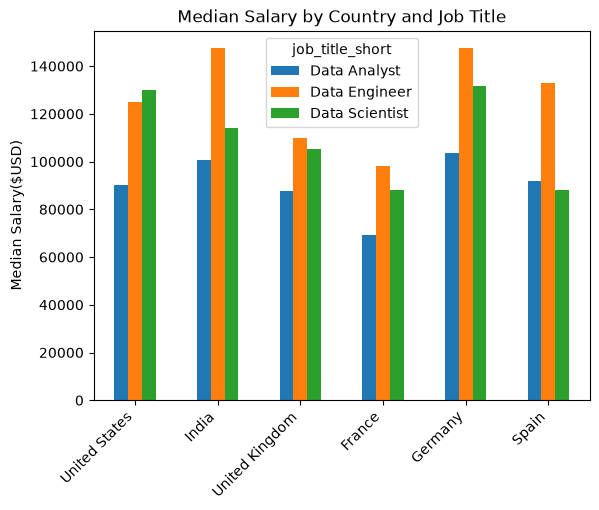

In [62]:
df_job_country_salary.plot(kind = 'bar')
plt.ylabel('Median Salary($USD)')
plt.xlabel('')
plt.title('Median Salary by Country and Job Title')
plt.xticks(rotation = 45, ha = 'right')
plt.show()

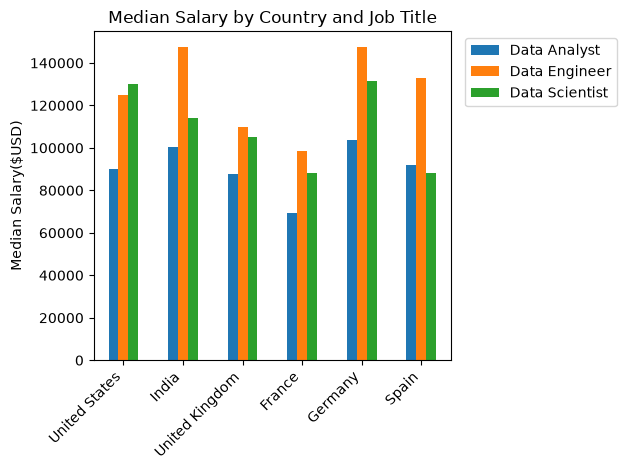

In [63]:


df_job_country_salary.plot(kind='bar')

plt.ylabel('Median Salary($USD)')
plt.xlabel('')
plt.title('Median Salary by Country and Job Title')
plt.xticks(rotation=45, ha='right')

# Move the legend outside to the upper right
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

# Adjust layout to prevent the legend from being cut off
plt.tight_layout()

plt.show()